# Notebook 1 : Nettoyage et préparation des données

**Projet** : Évolution de l'accès à un fournisseur habituel de soins de santé au Canada (2015-2022)

**Équipe** : Fatima Zohra Aboudeine · Safaa Namane · Badr Kabbadj · Mohamed Ali Alaoui

**Source** : Statistique Canada, tableau 13-10-0096-16 (ESCC)

| Ticket | Contenu |
|---|---|
| 18 | Spike : exploration et validation de la structure |
| 19 | Lignes de référence, lignes détaillées et drapeaux |
| 20 | Codes de qualité |
| 21 | Typage et format analytique |
| 22 | Variables de période |
| 23 | Contrôles de cohérence |
| 24 | Livrables : rapport d'audit et table nettoyée |

## Préparation de l'environnement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno

## Ticket 18 - Spike : exploration et validation de la structure du dataset

### Chargement et premier regard sur le fichier brut

In [2]:
df_raw = pd.read_csv('../data/13100096.csv', encoding="utf-8", low_memory=False)
df = df_raw.copy()
df.shape

(327165, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 327165 entries, 0 to 327164
Data columns (total 18 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   REF_DATE         327165 non-null  int64  
 1   GEO              327165 non-null  str    
 2   DGUID            300890 non-null  str    
 3   Age group        327165 non-null  str    
 4   Sex              327165 non-null  str    
 5   Indicators       327165 non-null  str    
 6   Characteristics  327165 non-null  str    
 7   UOM              327165 non-null  str    
 8   UOM_ID           327165 non-null  int64  
 9   SCALAR_FACTOR    327165 non-null  str    
 10  SCALAR_ID        327165 non-null  int64  
 11  VECTOR           327165 non-null  str    
 12  COORDINATE       327165 non-null  str    
 13  VALUE            248292 non-null  float64
 14  STATUS           136323 non-null  str    
 15  SYMBOL           0 non-null       float64
 16  TERMINATED       31950 non-null   str    
 17  DE

In [4]:
df.sample()

,REF_DATE,GEO,DGUID,Age group,Sex,Indicators,Characteristics,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
214268,2020,Ontario,2016A000235,18 to 34 years,Males,"Perceived mental health, fair or poor",Statistically different from previous referenc...,Number,223,units,0,v114670142,7.3.2.4.8,0.0,NaN,NaN,NaN,0


**Dictionnaire des variables du fichier brut**

| # | Variable | Type | Ce qu'elle représente | Décision prévue (à confirmer au ticket 21) |
|---|---|---|---|---|
| 1 | `REF_DATE` | entier | Année de référence de l'enquête | Garder (`annee`) |
| 2 | `GEO` | texte | Zone géographique | Garder (`geographie`) |
| 3 | `DGUID` | texte | Identifiant géographique unique de StatCan | Garder pour la jointure avec la carte (ticket 32) |
| 4 | `Age group` | texte | Groupe d'âge de la population | Garder (`age`) |
| 5 | `Sex` | texte | Sexe | Garder (`sexe`) |
| 6 | `Indicators` | texte | Indicateur de santé mesuré (32 sujets) | Une seule valeur après filtre : retirer de la table analytique |
| 7 | `Characteristics` | texte | Nature de la mesure de la ligne (6 estimations + 3 drapeaux) | Garder (sert au pivot) |
| 8 | `UOM` | texte | Unité de mesure | Retirer (déduite de `Characteristics`) |
| 9 | `UOM_ID` | entier | Code numérique de l'unité | Retirer |
| 10 | `SCALAR_FACTOR` | texte | Facteur d'échelle des valeurs | Retirer (constante : « units ») |
| 11 | `SCALAR_ID` | entier | Code du facteur d'échelle | Retirer (constante : 0) |
| 12 | `VECTOR` | texte | Identifiant de la série chronologique StatCan | Retirer (identifiant technique) |
| 13 | `COORDINATE` | texte | Position de la série dans le cube (code de chaque dimension) | Retirer (identifiant technique) |
| 14 | `VALUE` | décimal | La valeur mesurée (nombre de personnes, pourcentage, borne d'IC, ou code du drapeau) | Garder (`valeur`, puis colonnes du pivot) |
| 15 | `STATUS` | texte | Symbole de qualité de la valeur | Garder (`qualite`) |
| 16 | `SYMBOL` | décimal | Entièrement vide | Retirer |
| 17 | `TERMINATED` | texte | Marque une série que StatCan a arrêtée de mettre à jour | Garder comme information (à vérifier) |
| 18 | `DECIMALS` | entier | Nombre de décimales publié | Retirer (déduite de `UOM`) |

**Granularité** : une ligne = une année × une géographie × un groupe d'âge × un sexe × un indicateur × une caractéristique.

### Choix de l'indicateur

In [5]:
(df["Indicators"].value_counts(normalize=True) * 100).round(2)

Indicators
Influenza immunization in the past 12 months                                               3.91
Perceived health, very good or excellent                                                   3.85
Perceived health, fair or poor                                                             3.85
Perceived mental health, very good or excellent                                            3.85
Perceived mental health, fair or poor                                                      3.85
Perceived life stress, most days quite a bit or extremely stressful                        3.85
Arthritis (15 years and over)                                                              3.85
Diabetes                                                                                   3.85
Asthma                                                                                     3.85
Chronic obstructive pulmonary disease (COPD; 35 years and over)                            3.85
High blood pressure          

Le fichier couvre plusieurs sujets de santé publique (32 indicateurs). Nos questions Q1 à Q6 portent uniquement sur l'accès à un fournisseur habituel de soins : nous isolons donc l'indicateur **« Has a regular healthcare provider »**.

In [6]:
df_hp = df[df["Indicators"] == "Has a regular healthcare provider"].copy()

print(f"{len(df_hp)} lignes ({len(df_hp)/len(df):.1%} du fichier)")

12591 lignes (3.8% du fichier)


### Conclusion du Spike : structure du tableau 13-10-0096-16

**Contrôles de volume :**
- Le fichier brut compte **327 165 lignes** et **18 colonnes**, conformément à la note de cadrage.
- Il contient **32 indicateurs**. Notre indicateur, « Has a regular healthcare provider », représente **12 591 lignes (3,8 %)**.

## Ticket 19 : Lignes de référence, lignes détaillées et drapeaux :

**Années**

In [7]:
df_hp["REF_DATE"].value_counts().sort_index()

REF_DATE
2015    1368
2016    1566
2017    1566
2018    1566
2019    1566
2020    1566
2021    1566
2022    1827
Name: count, dtype: int64

Le nombre d'observations est constant de 2016 à 2021 (1 566 lignes par an). L'année 2015 enregistre un volume plus faible (1 368 lignes), tandis que 2022 présente le volume le plus élevé (1 827 lignes).

**Géographies**

In [8]:
df_hp["GEO"].value_counts()

GEO
Newfoundland and Labrador         1158
Prince Edward Island              1158
Nova Scotia                       1158
New Brunswick                     1158
Quebec                            1158
Ontario                           1158
Manitoba                          1158
Saskatchewan                      1158
Alberta                           1158
British Columbia                  1158
Canada (excluding territories)    1011
Name: count, dtype: int64

**Ligne de référence :** La modalité **Canada (excluding territories)** représente la référence nationale et servira à évaluer la situation de chaque province. Elle permettra de déterminer par exemple si une province se situe au-dessus ou en dessous de la moyenne canadienne (par exemple, pour comparer taux national).

**Groupes d'âge**

In [9]:
df_hp["Age group"].value_counts()

Age group
Total, 12 years and over    2055
12 to 17 years              2055
18 to 34 years              2055
35 to 49 years              2055
50 to 64 years              2055
65 years and over           2055
Total, 18 years and over     261
Name: count, dtype: int64

In [10]:
pd.crosstab(df_hp['REF_DATE'], df_hp['Age group'])

Age group,12 to 17 years,18 to 34 years,35 to 49 years,50 to 64 years,65 years and over,"Total, 12 years and over","Total, 18 years and over"
REF_DATE,,,,,,,
2015,228,228,228,228,228,228,0
2016,261,261,261,261,261,261,0
2017,261,261,261,261,261,261,0
2018,261,261,261,261,261,261,0
2019,261,261,261,261,261,261,0
2020,261,261,261,261,261,261,0
2021,261,261,261,261,261,261,0
2022,261,261,261,261,261,261,261


**Validation temporelle des tranches d'âge (REF_DATE x Age group) :**

- Les 5 tranches d'âge détaillées ainsi que le groupe Total, 12 years and over présentent un volume identique chaque année (228 lignes en 2015, puis 261 lignes par an de 2016 à 2021).

- La ligne 2022 affiche la valeur 261 pour Total, 18 years and over, alors qu'elle est à 0 sur toutes les années précédentes. Cela confirme que cette catégorie a été ajoutée uniquement lors de la vague 2022.

**Conséquence pour le filtrage :** Lors des analyses temporelles, la catégorie **Total, 12 years and over** doit être privilégiée pour maintenir une série temporelle continue et homogène sur toute la période.

**Sexe**

In [11]:
df_hp["Sex"].value_counts()

Sex
Both sexes    4197
Males         4197
Females       4197
Name: count, dtype: int64

Règle de filtrage pour nos analyses :

- **Pour analyser la population globale :** filtrer sur df['Sex'] == 'Both sexes'.

- **Pour comparer les hommes et les femmes :**
filtrer sur df['Sex'] == ['Males'] ou filtrer sur df['Sex'] == ['Females']

**Caractéristiques** (nature de chaque ligne)

In [12]:
df_hp["Characteristics"].value_counts()

Characteristics
Number of persons                                                       1617
Low 95% confidence interval, number of persons                          1617
High 95% confidence interval, number of persons                         1617
Percent                                                                 1617
Low 95% confidence interval, percent                                    1617
High 95% confidence interval, percent                                   1617
Statistically different from previous reference period                  1419
Statistically different from the Canada (excluding territories) rate    1260
Statistically different from the rest of Canada                          210
Name: count, dtype: int64

**Nature des lignes (Characteristics) :**

La variable Characteristics définit la nature de chaque mesure. Elle se compose de 6 lignes d'estimations (le nombre absolu de personnes et le pourcentage, accompagnés de leurs bornes d'intervalle de confiance à 95 %) et de 3 lignes de drapeaux statistiques. Ces drapeaux indiquent si l'écart observé est significatif par rapport à la période précédente, à la moyenne canadienne ou au reste du pays. Les 6 premières servent à pivoter la table pour structurer le tableau analytique, tandis que les 3 dernières fournissent des éléments de validation statistique.

**Les trois lignes de drapeaux « Statistically different… »**

In [13]:
flags = df_hp[df_hp["Characteristics"].str.startswith("Statistically different")]
pd.crosstab(flags["Characteristics"], flags["REF_DATE"])

REF_DATE,2015,2016,2017,2018,2019,2020,2021,2022
Characteristics,,,,,,,,
Statistically different from previous reference period,0,198,198,198,198,198,198,231
Statistically different from the Canada (excluding territories) rate,180,180,180,180,180,180,180,0
Statistically different from the rest of Canada,0,0,0,0,0,0,0,210


On a séparé ces lignes pour ne pas mélanger deux types d'informations complètement différents lors des calculs:
* **Les mesures (pourcentages, nombre de personnes) :** C'est la vraie donnée sur l'accès aux soins.  
* **Les drapeaux statistiques :** Ce sont de simples codes (0, 1, -1) indiquant si l'écart avec la moyenne nationale ou l'année précédente est significatif.

In [14]:
flags.groupby("Characteristics")["VALUE"].value_counts(dropna=False)

Characteristics                                                       VALUE
Statistically different from previous reference period                 0.0     1070
                                                                       NaN      231
                                                                       1.0       74
                                                                      -1.0       44
Statistically different from the Canada (excluding territories) rate   0.0      735
                                                                       1.0      288
                                                                      -1.0      237
Statistically different from the rest of Canada                        0.0       96
                                                                       1.0       54
                                                                      -1.0       50
                                                                       NaN       10


### Valeurs manquantes et symboles de qualité

In [15]:
df_hp.isna().sum()

REF_DATE               0
GEO                    0
DGUID               1011
Age group              0
Sex                    0
Indicators             0
Characteristics        0
UOM                    0
UOM_ID                 0
SCALAR_FACTOR          0
SCALAR_ID              0
VECTOR                 0
COORDINATE             0
VALUE                319
STATUS             12162
SYMBOL             12591
TERMINATED         11331
DECIMALS               0
dtype: int64

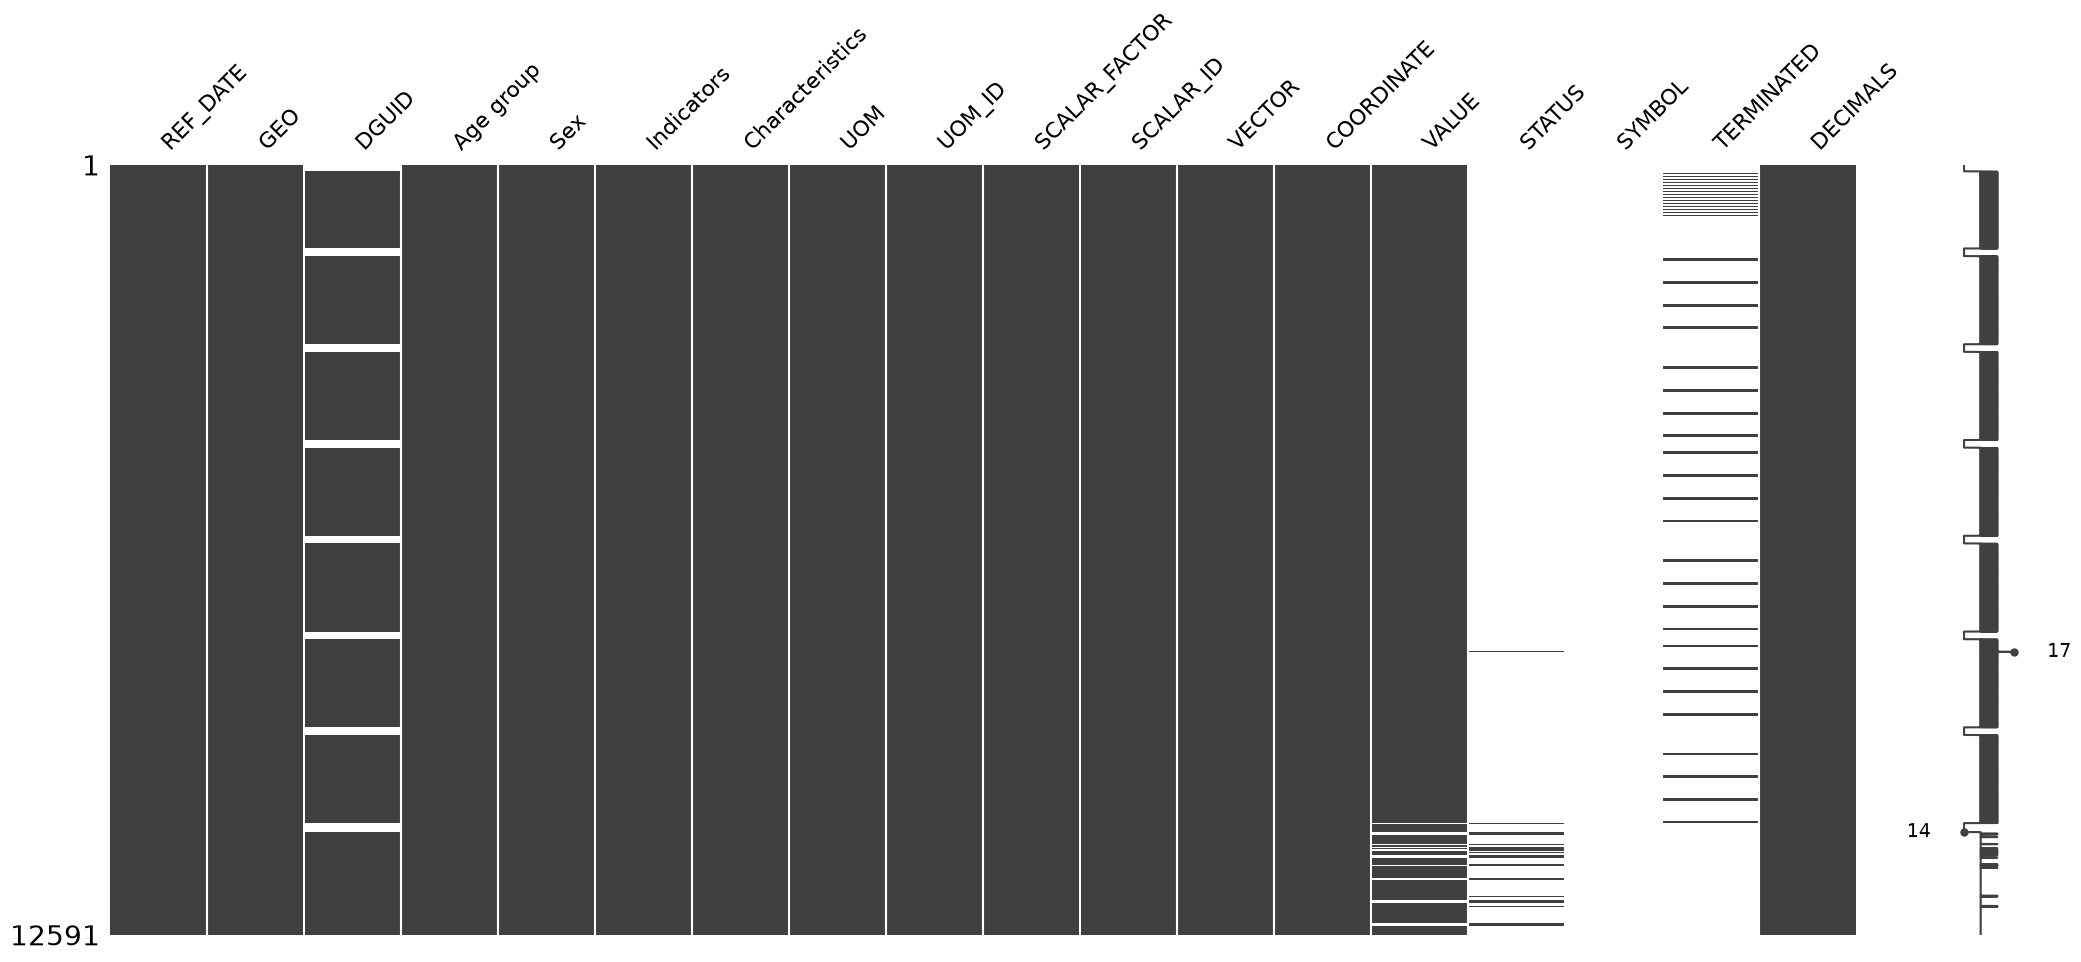

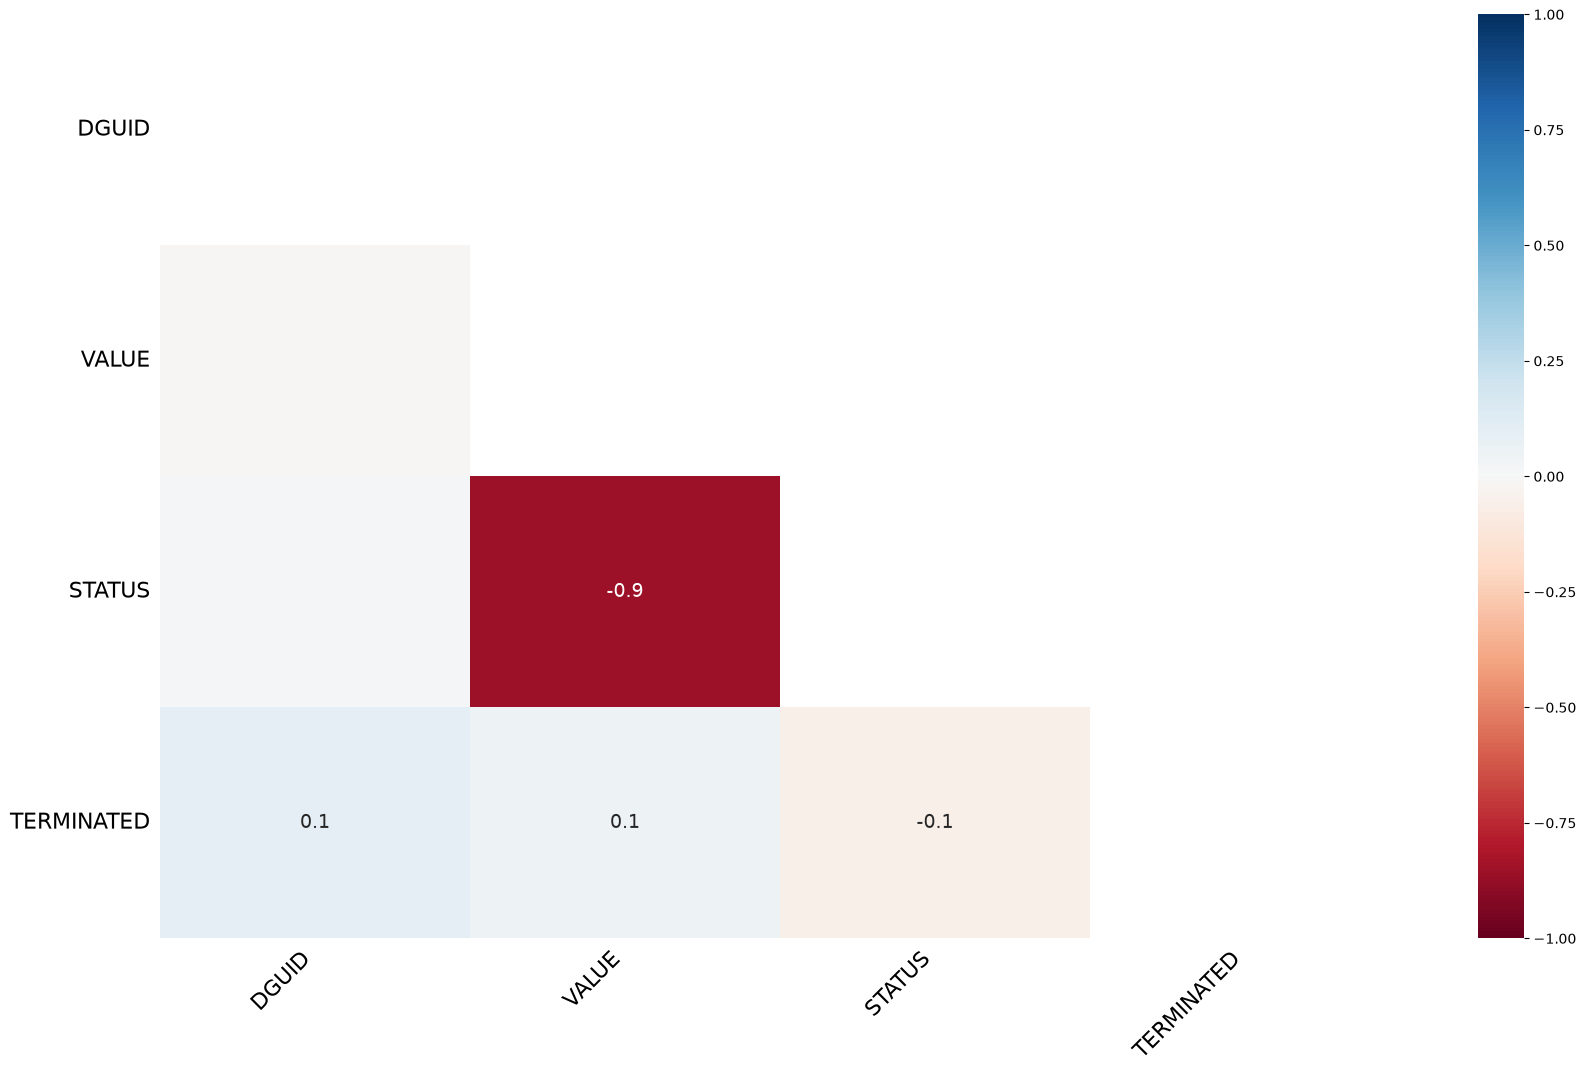

In [16]:
msno.matrix(df_hp)
plt.show()

msno.heatmap(df_hp)
plt.show()

***Analyse de la qualité des données et des valeurs manquantes :***

* **Excellente complétude des variables structurelles :** Aucune valeur manquante dans l'ensemble des colonnes principales (date, géographie, âge, sexe, caractéristiques, unités), ce qui garantit la fiabilité de la structure générale de notre jeu de données.

* **La variable cible (VALUE) :** Les 3 191 valeurs manquantes sur la colonne VALUE correspondent à des suppressions ou des masquages appliqués par StatCan (par exemple, pour des raisons de confidentialité ou de faible fiabilité statistique due à un échantillon restreint).

* **Métadonnées optionnelles :** Les volumes élevés de valeurs manquantes dans les colonnes STATUS, SYMBOL et TERMINATED sont attendus, car ces attributs ne servent qu'à annoter des situations ou des exceptions particulières.

Sur l'ensemble des colonnes structurelles (REF_DATE, GEO, Age group, Sex, Characteristics, Indicators et UOM), la complétude est totale (0 % de données manquantes), ce qui garantit l'intégrité du cadre d'analyse. 

* **Pour la variable DGUID**, l'absence de valeurs concerne uniquement l'agrégat national « Canada (excluding territories) » ; il s'agit d'un manque d'information de nature non applicable (et non d'une erreur), conservé en l'état sans imputation. 

* **Pour la variable cible VALUE**, les 3 191 cases vides sont entièrement expliquées par les codes officiels de la colonne STATUS (.. pour non applicable, x pour confidentialité et F pour suppression liée à une trop faible fiabilité statistique). Ce processus d'absence répond à un mécanisme MNAR (Missing Not At Random), où la donnée est masquée en fonction de sa propre valeur ou de contraintes réglementaires de censure. Conformément aux préconisations théoriques, toute imputation univariée (SimpleImputer) ou multivariée (KNNImputer, IterativeImputer) sur du MNAR introduirait un biais d'estimation critique et déformerait artificiellement les distributions. Par conséquent, aucune suppression de lignes par dropna() ni imputation par fillna() n'a été appliquée sur VALUE ; les lignes non fiables (x et F) ont été écartées lors du filtrage de qualité tout en préservant l'information binaire du drapeau STATUS. 

* Enfin, **la variable SYMBOL** entièrement vide (100 % de NaN) et **la colonne TERMINATED** (présentant 90 % d'absences dues à l'arrêt d'une série spécifique par Statistique Canada) ont été traitées respectivement par suppression de la colonne inutile pour SYMBOL et par simple conservation à titre informatif pour TERMINATED.

**Les `DGUID` vides correspondent-ils tous au Canada ?**

In [17]:
df_hp.loc[df_hp["DGUID"].isna(), "GEO"].value_counts()

GEO
Canada (excluding territories)    1011
Name: count, dtype: int64

Lignes « Canada (excluding territories) » : le Canada n'a pas de code de province. Vide normal, pas une erreur.

**Les cases vides de `VALUE` sont-elles toutes expliquées par un symbole ?**

In [18]:
pd.crosstab(df_hp["STATUS"], df_hp["VALUE"].isna(), dropna=False)

VALUE,False,True
STATUS,,
..,0,231
E,110,0
F,0,81
x,0,7
NaN,12162,0


Voici la signification de chacun de ces symboles :

- **.. (deux points) :** Non disponible pour une période de référence spécifique (ou non applicable).

- **E :** À utiliser avec prudence. La donnée présente une variabilité échantillonnable élevée.

- **F :** Trop peu fiable pour être publiée. La donnée a été supprimée car la marge d'erreur est trop grande.

- **x :** Confidentiel. La valeur est masquée pour protéger l'identité des répondants en vertu de la Loi sur la statistique.

- **Validation méthodologique des valeurs manquantes (STATUS vs VALUE.isna()) :** Justification intégrale des données masquées ($3\ 191$ cas) : L'ensemble des lignes où la colonne VALUE est absente (VALUE = True) est rigoureusement expliqué par les codes de statut de Statistique Canada : l'indisponibilité pour non-applicabilité (..), la confidentialité (x) et la suppression pour faible fiabilité statistique (E et F).

- **Fiabilité des données publiées ($12\ 162$ cas) :** L'intégralité des observations renseignées (VALUE = False) ne présente aucun code de restriction (STATUS = NaN), ce qui garantit leur parfaite exploitabilité pour l'analyse analytique et cartographique.

**La colonne `TERMINATED` correspond-elle à un seul drapeau ?**

In [19]:
pd.crosstab(df_hp["Characteristics"], df_hp["TERMINATED"].fillna("(vide)"))

TERMINATED,(vide),t
Characteristics,,
"High 95% confidence interval, number of persons",1617,0
"High 95% confidence interval, percent",1617,0
"Low 95% confidence interval, number of persons",1617,0
"Low 95% confidence interval, percent",1617,0
Number of persons,1617,0
Percent,1617,0
Statistically different from previous reference period,1419,0
Statistically different from the Canada (excluding territories) rate,0,1260
Statistically different from the rest of Canada,210,0


### Diagnostic des valeurs manquantes (indicateur « Has a regular healthcare provider », 12 591 lignes)

| Colonne | Manquantes | Interprétation | Décision |
|---|---|---|---|
| `DGUID` | 1 011 (8,0 %) | Lignes « Canada (excluding territories) » : le Canada n'a pas de code de province. Vide **normal**, pas une erreur. | Aucune action. |
| `VALUE` | 319 (2,5 %) | Cases vides expliquées par un symbole dans `STATUS` : `..` (231) + `F` (81) + `x` (7) = 319. | **Pas d'imputation.** Les cases sont conservées avec un drapeau de qualité (ticket 20). |
| `STATUS` | 12 162 (96,6 %) | Vide = **aucun symbole**, donc valeur sans réserve. Ce n'est pas un manque d'information. | Aucune action|
| `SYMBOL` | 12 591 (100 %) | Colonne entièrement vide. | Retirer de la table analytique |
| `TERMINATED` | 11 331 (90,0 %) | Rempli (`t`) sur 1 260 lignes, soit le même nombre que le drapeau « Statistically different from the Canada (excluding territories) rate ». Cette série semble arrêtée par Statistique Canada | Conservée comme information. Nous ne nous appuierons pas sur ce drapeau pour les écarts à la référence canadienne. |

Les 12 autres colonnes n'ont aucune valeur manquante.

**Constat.** Le mot « manquant » recouvre ici trois situations différentes :
1. **non applicable** (`DGUID` pour le Canada) ;
2. **supprimée ou non publiée par Statistique Canada** (`VALUE`, expliquée par `F`, `x` ou `..`) ;
3. **rien à signaler** (`STATUS` vide).

Aucune case de `VALUE` n'est vide sans symbole : il n'y a donc pas d'oubli ni d'erreur de saisie à réparer.

**Décision.** Nous n'utilisons ni `dropna()` ni `fillna()`. Supprimer les lignes retirerait tout le Canada (8 % du fichier). Imputer des moyennes inventerait des valeurs que Statistique Canada a volontairement retirées pour cause de non-disponibilité, de faible fiabilité ou de confidentialité. Cette décision applique le ticket 20 du backlog.

## Ticket 20 : Gestion des codes de qualité :

Dans le dictionnaire StatCan, un STATUS vide signifie une valeur valide sans réserve. Nous allons donc remplacer les cellules vides de STATUS par 'aucun' pour leur donner du sens :

### Nettoyage de STATUS :

In [20]:
df_hp['STATUS'] = df_hp['STATUS'].fillna('aucun')

### Nettoyage de SYMBOL (entièrement vide, 100% NaN) :

In [21]:
if 'SYMBOL' in df_hp.columns:
    df_hp = df_hp.drop(columns=['SYMBOL'])

### Application du filtre de qualité officiel StatCan :

- EXCLUSION : 'x' (confidentialité) et 'F' (faible fiabilité / variabilité excessive)
- CONSERVATION : 'E' (à utiliser avec précaution) et 'aucun' (valeur sûre)

In [22]:
df_filtered = df_hp[~df_hp['STATUS'].isin(['x', 'F'])].copy()

### Affichage du rapport de contrôle du filtrage de qualité :

In [23]:
print(f"Lignes initiales (indicateur cible) : {len(df_hp)}")
print(f"Lignes après suppression des status 'F' et 'x' : {len(df_filtered)}")
print(f"Lignes exclues (non fiables ou confidentielles) : {len(df_hp) - len(df_filtered)}")
print("\nRépartition des statuts de qualité conservés :")
print(df_filtered['STATUS'].value_counts(dropna=False))

Lignes initiales (indicateur cible) : 12591
Lignes après suppression des status 'F' et 'x' : 12503
Lignes exclues (non fiables ou confidentielles) : 88

Répartition des statuts de qualité conservés :
STATUS
aucun    12162
..         231
E          110
Name: count, dtype: int64


## Ticket 21 : Typage des variables et passage au format analytique :

Les colonnes inutiles identifiées dans notre Spike vont être supprimées dans cette étape :

### Suppression des colonnes inutiles :

In [24]:
cols_inutiles = [
    'UOM', 'UOM_ID', 'SCALAR_FACTOR', 'SCALAR_ID',
    'VECTOR', 'COORDINATE', 'DECIMALS'
]
df_filtered = df_filtered.drop(columns=[c for c in cols_inutiles if c in df_filtered.columns])

### Séparation des mesures réelles et drapeaux statistiques :


Séparation des mesures réelles d'accès aux soins vs les drapeaux d'écart statistique (Pour ne pas mélanger des pourcentages avec des codes 0, 1, -1 lors des calculs) :

In [25]:
is_flag = df_filtered['Characteristics'].str.startswith('Statistically different')
df_measures = df_filtered[~is_flag].copy()
df_flags = df_filtered[is_flag].copy()

### Conversion du champ VALUE en numérique continu :

In [26]:
df_measures['VALUE'] = pd.to_numeric(df_measures['VALUE'], errors='coerce')

### Transformation du jeu de données du format long vers un format wide (analytique) :

In [27]:
# Dictionnaire de reformatage des noms de caractéristiques (Pivotement)
char_map = {
    'Number of persons': 'val_number',
    'Low 95% confidence interval, number of persons': 'ci_low_number',
    'High 95% confidence interval, number of persons': 'ci_high_number',
    'Percent': 'val_percent',
    'Low 95% confidence interval, percent': 'ci_low_percent',
    'High 95% confidence interval, percent': 'ci_high_percent'
}
df_measures['char_clean'] = df_measures['Characteristics'].map(char_map)

In [28]:
# Pivotement : Obtenir une ligne unique par cellule (REF_DATE x GEO x DGUID x Age group x Sex)
index_cols = ['REF_DATE', 'GEO', 'Age group', 'Sex']

In [29]:
df_pivoted = df_measures.pivot_table(
    index=index_cols,
    columns='char_clean',
    values='VALUE',
    aggfunc='first',
    dropna=False
).reset_index()

In [30]:
# Récupération du statut de qualité principal (associé à la mesure 'val_percent') :
df_status = df_measures[df_measures['char_clean'] == 'val_percent'][index_cols + ['STATUS']]

In [31]:
# Fusion finale :
df_analytic = pd.merge(df_pivoted, df_status, on=index_cols, how='left')

In [32]:
# RAPPORT DU PIVOTEMENT ET TYPAGE (TICKETS 21)
print("--- SUCCÈS DU PIVOTEMENT ET DUB TYPAGE (TICKET 21) ---")
print(f"Dimensions de la table analytique pivotée : {df_analytic.shape}")
print(f"Colonnes générées dans df_analytic : {df_analytic.columns.tolist()}")

--- SUCCÈS DU PIVOTEMENT ET DUB TYPAGE (TICKET 21) ---
Dimensions de la table analytique pivotée : (1848, 11)
Colonnes générées dans df_analytic : ['REF_DATE', 'GEO', 'Age group', 'Sex', 'ci_high_number', 'ci_high_percent', 'ci_low_number', 'ci_low_percent', 'val_number', 'val_percent', 'STATUS']


In [33]:
df_analytic.sample()

,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS
721,2018,British Columbia,35 to 49 years,Females,418200.0,88.3,382400.0,80.8,401700.0,84.9,aucun


## Ticket 22 : Création des variables de période :

Cette étape ajoute à la table analytique les variables temporelles requises pour l'analyse des tendances, la prise en compte de la pandémie de COVID-19 et la gestion de la rupture méthodologique de Statistique Canada en 2022.

### Découpage souhaité :

* Avant 2020 (Pre-COVID) : Période de référence historique (2015 à 2019).

* 2020-2021 (Pandémie) : Période de perturbations majeures du système de santé.

* 2022 et après (Post-COVID) : Période de reprise / situation récente.

### Rupture méthodologique :

* Statistique Canada a ajusté la formulation de la question de l'ESCC en 2022.

* La variable binaire is_post_2022_methodology (ou PERIOD_SURVEY) permet d'isoler cette rupture dans les modèles et visualisations.

In [34]:
# Variable catégorielle pour la segmentation par période COVID :
df_analytic['PERIOD_COVID'] = np.where(
    df_analytic['REF_DATE'] < 2020, 'Avant 2020 (Pre-COVID)',
    np.where(
        df_analytic['REF_DATE'] <= 2021, '2020-2021 (Pandémie)',
        '2022 et après (Post-COVID)'
    )
)

In [35]:
df_analytic['PERIOD_COVID'].value_counts()

PERIOD_COVID
Avant 2020 (Pre-COVID)        1155
2020-2021 (Pandémie)           462
2022 et après (Post-COVID)     231
Name: count, dtype: int64

In [36]:
# Variable binaire de rupture méthodologique (StatCan 2022) :
df_analytic['is_post_2022_methodology'] = (df_analytic['REF_DATE'] >= 2022).astype(int)
df_analytic['is_post_2022_methodology'].value_counts()

is_post_2022_methodology
0    1617
1     231
Name: count, dtype: int64

In [37]:
# Libellé clair de la période d'enquête
df_analytic['PERIOD_SURVEY'] = np.where(
    df_analytic['REF_DATE'] < 2022,
    'Ancienne méthodologie (2015-2021)',
    'Nouvelle méthodologie (2022+)'
)
df_analytic.sample()

,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS,PERIOD_COVID,is_post_2022_methodology,PERIOD_SURVEY
1301,2020,Nova Scotia,"Total, 18 years and over",Males,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-2021 (Pandémie),0,Ancienne méthodologie (2015-2021)


### Vérification de la pertinence des variables de période :

In [38]:
pd.crosstab(df_analytic['REF_DATE'], df_analytic['PERIOD_SURVEY'])

PERIOD_SURVEY,Ancienne méthodologie (2015-2021),Nouvelle méthodologie (2022+)
REF_DATE,,
2015,231,0
2016,231,0
2017,231,0
2018,231,0
2019,231,0
2020,231,0
2021,231,0
2022,0,231


## Ticket 23 : Contrôle de la cohérence des données :

### Vérification des bornes de pourcentage (val_percent) :

In [39]:
# Contrôle des plages de valeurs (Pourcentages entre 0 et 100)
out_of_bounds_pct = df_analytic[
    (df_analytic['val_percent'] < 0) | (df_analytic['val_percent'] > 100)
]
print(f"Pourcentages hors limites [0, 100] : {len(out_of_bounds_pct)}")

Pourcentages hors limites [0, 100] : 0


### Cohérence des intervalles de confiance (IC à 95 %) :

In [40]:
# On ignore les lignes où les IC sont NaN (données masquées/exclues)
valid_ic = df_analytic.dropna(subset=['ci_low_percent', 'val_percent', 'ci_high_percent'])

inconsistent_ic_low = valid_ic[valid_ic['ci_low_percent'] > valid_ic['val_percent']]
inconsistent_ic_high = valid_ic[valid_ic['val_percent'] > valid_ic['ci_high_percent']]

print(f"Anomalies IC Inférieur (ci_low > val) : {len(inconsistent_ic_low)}")
print(f"Anomalies IC Supérieur (val > ci_high) : {len(inconsistent_ic_high)}")

Anomalies IC Inférieur (ci_low > val) : 0
Anomalies IC Supérieur (val > ci_high) : 0


### Cohérence des effectifs (val_number) :

In [41]:
negative_counts = df_analytic[df_analytic['val_number'] < 0]
print(f"Effectifs de personnes négatifs : {len(negative_counts)}")

Effectifs de personnes négatifs : 0


### Intégrité de l'index et absence de doublons :

In [42]:
# Contrôle des doublons sur la clé primaire
primary_key = ['REF_DATE', 'GEO', 'Age group', 'Sex']
nb_duplicates = df_analytic.duplicated(subset=primary_key).sum()
print(f"Doublons sur la clé primaire {primary_key} : {nb_duplicates}")
assert nb_duplicates == 0, "ERREUR : Des doublons existent sur la clé primaire !"

Doublons sur la clé primaire ['REF_DATE', 'GEO', 'Age group', 'Sex'] : 0


Aucune anomalie, nous allons donc continuer notre prétraitement.

## Ticket 24 : Livrables :

In [44]:
df_analytic.to_csv('../data/table_analytique_nettoyee.csv', index=False, encoding='utf-8')

## Ticket 25 : L'évolution nationale de l'accès

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/table_analytique_nettoyee.csv')

df.head()

,REF_DATE,GEO,Age group,Sex,ci_high_number,ci_high_percent,ci_low_number,ci_low_percent,val_number,val_percent,STATUS,PERIOD_COVID,is_post_2022_methodology,PERIOD_SURVEY
0,2015,Alberta,12 to 17 years,Both sexes,226000.0,85.8,200500.0,76.6,213300.0,81.2,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
1,2015,Alberta,12 to 17 years,Females,110800.0,87.6,91900.0,73.2,101400.0,80.4,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
2,2015,Alberta,12 to 17 years,Males,120200.0,87.7,103600.0,76.1,111900.0,81.9,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
3,2015,Alberta,18 to 34 years,Both sexes,770200.0,71.3,697700.0,64.6,733900.0,68.0,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)
4,2015,Alberta,18 to 34 years,Females,440900.0,83.5,398300.0,75.4,419600.0,79.5,aucun,Avant 2020 (Pre-COVID),0,Ancienne méthodologie (2015-2021)


In [6]:
REF_GEO,REF_AGE,REF_SEX='Canada (excluding territories)','Total, 12 years and over','Both sexes'
nat=df[(df['GEO']==REF_GEO)&(df['Age group']==REF_AGE)&(df['Sex']==REF_SEX)].sort_values('REF_DATE')
assert nat['REF_DATE'].tolist()==list(range(2015,2023))
serie=pd.DataFrame({'annee':nat['REF_DATE'].values,'acces':nat['val_percent'].values})
serie

,annee,acces
0,2015,83.2
1,2016,84.2
2,2017,84.7
3,2018,85.3
4,2019,85.5
5,2020,85.8
6,2021,85.5
7,2022,86.0


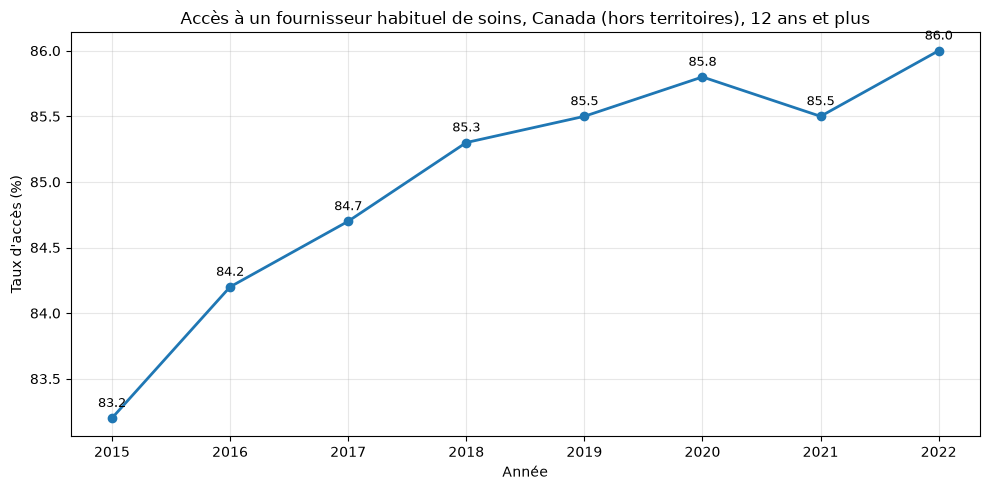

Graphique enregistré : C:\Users\naman\Downloads\PAD-main\PAD-main\notebooks\resultats\tendance_nationale_acces.png


In [7]:
# 1. Définir le dossier de sauvegarde
OUT_DIR = "resultats"
os.makedirs(OUT_DIR, exist_ok=True)

# 2. Créer le graphique
fig, ax = plt.subplots(figsize=(10, 5))

# 3. Tracer la tendance nationale
ax.plot(
    serie['annee'],
    serie['acces'],
    marker='o',
    linewidth=2
)

# 4. Afficher les valeurs sur le graphique
for a, v in zip(serie['annee'], serie['acces']):
    ax.annotate(
        f"{v:.1f}",
        (a, v),
        textcoords='offset points',
        xytext=(0, 8),
        ha='center',
        fontsize=9
    )

# 5. Personnaliser le graphique
ax.set_xticks(serie['annee'])
ax.set_xlabel('Année')
ax.set_ylabel("Taux d'accès (%)")

ax.set_title(
    "Accès à un fournisseur habituel de soins, "
    "Canada (hors territoires), 12 ans et plus"
)

ax.grid(alpha=0.3)

# 6. Ajuster la présentation
plt.tight_layout()

# 7. Enregistrer le graphique
chemin = os.path.join(
    OUT_DIR,
    'tendance_nationale_acces.png'
)

fig.savefig(
    chemin,
    dpi=200,
    bbox_inches='tight'
)

# 8. Afficher le graphique
plt.show()

# 9. Confirmer l'enregistrement
print("Graphique enregistré :", os.path.abspath(chemin))
